# Basis functions: Zernike, Legendre, Chebyshev and orthogonalized sets

Wavefronts, surface deviations and phase masks are usually described by a
handful of coefficients in a **basis set**: $W(x, y) = \sum_j c_j B_j(x, y)$.
`pyoptics.bases` provides these sets with a common interface:

| call | meaning |
|---|---|
| `B(indices, coeffs)` | evaluate $\sum_j c_j B_j$ on the grid given at construction |
| `B(indices, coeffs, x, y)` | evaluate at scattered points |
| `B.eval_single(j)` | a single sampled basis function |
| `B.mask` | the support (circle, square, ...) |
| `B.normalization_factor(j)` | the analytic norm $\langle B_j \vert B_j \rangle$ |
| `B.coeffs_from_field(W, indices, method)` | expansion by least squares (`"LSTSQ"`) or overlap integrals (`"DI"`) |
| `B.coeffs_from_scattered(x, y, data, indices)` | least-squares fit to scattered samples |

The concrete sets are `FringeZernikes` (circular apertures),
`LegendrePolynomials` and `ChebyshevPolynomials` (rectangular apertures),
plus the wrappers `PresampledBasisSet`, `NumericallyOrthogonalized` (Gram-Schmidt
on an arbitrary aperture) and `RescaledBasis`.

This notebook is about the bases themselves: what they look like, in which
sense they are orthogonal, and why orthogonality on the *actual* aperture
matters. Notebook 05 uses the Zernikes for aberrations and the PSF.

In [1]:
import contextlib
import io
import time

import numpy as np
import matplotlib.pyplot as plt

from pyoptics.bases import (FringeZernikes, LegendrePolynomials, ChebyshevPolynomials,
                            PresampledBasisSet, NumericallyOrthogonalized, RescaledBasis,
                            fringe_to_n_m, fringe_zernike_R_nm, fringe_zernike_norm,
                            poly_basis_size)
from pyoptics.masks import circular_mask, annular_mask, mask_from_polygon
from pyoptics.utils import grid1d, scalar_product

plt.rcParams.update({"figure.dpi": 100, "image.origin": "lower", "font.size": 11})

def gram(funcs, x, y, weights=1.0):
    """Gram matrix G_ij = <B_i|B_j> = sum(w B_i B_j) dx dy of real sampled functions."""
    F = np.array([f.ravel() for f in funcs])
    dx, dy = x[1] - x[0], y[1] - y[0]
    return (F*np.ravel(weights*np.ones_like(funcs[0])))@F.T*dx*dy

def correlation(G):
    """|G_ij|/sqrt(G_ii G_jj): the cosine of the 'angle' between two functions.

    Exact zeros are raised to 1e-15 so that they show up on logarithmic colour scales."""
    d = np.sqrt(np.diag(G))
    return np.maximum(np.abs(G/np.outer(d, d)), 1e-15)

def show(ax, data, mask, extent, title, vmax=None, cmap="RdBu_r"):
    data = np.where(mask, data, np.nan)
    vmax = np.nanmax(np.abs(data)) if vmax is None else vmax
    im = ax.imshow(data, cmap=cmap, vmin=-vmax, vmax=vmax, extent=extent)
    ax.set_title(title, fontsize=9); ax.axis("off")
    return im

## 1. The Zernike pyramid

A Zernike polynomial is a radial polynomial times an azimuthal harmonic,
$Z_n^m(\rho, \varphi) = R_n^{|m|}(\rho)\,\{\cos, \sin\}(|m|\varphi)$, with
$n - |m|$ even. Arranged by radial order $n$ (rows) and azimuthal order $m$
(columns), they form a pyramid. The Fringe index $j$ (shown in each panel) runs
through the pyramid in a different order: it groups the functions by
$(n + |m|)/2$, so that e.g. $Z_9$ (primary spherical) comes before the
trefoils $Z_{10}, Z_{11}$, even though trefoil has $n = 3$.

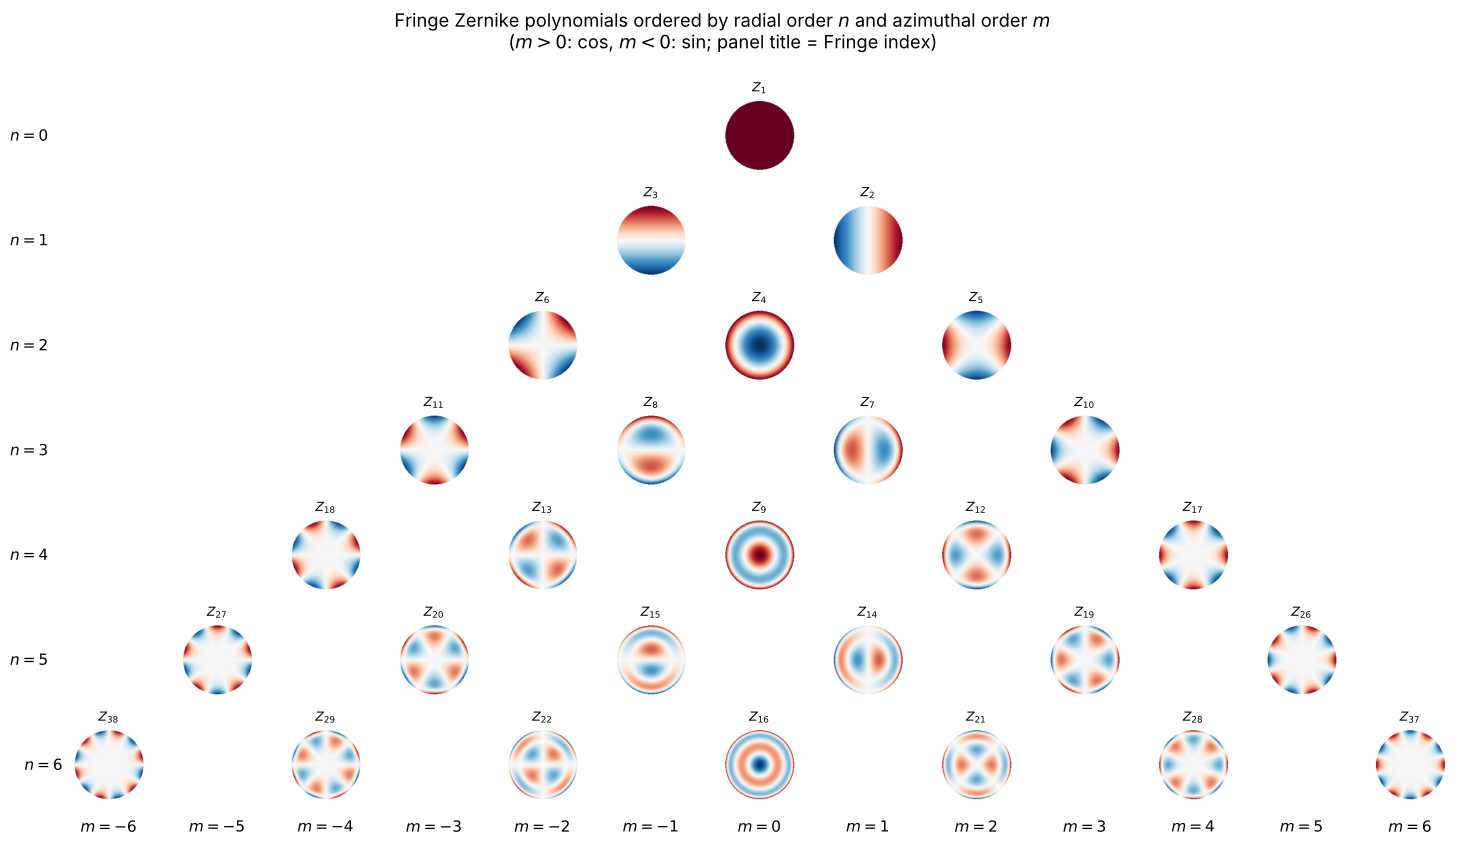

In [2]:
xg = grid1d(-1.02, 1.02, 161)
Zg = FringeZernikes(xg, xg)
mask_g = Zg.mask.astype(bool)
ext = (xg[0], xg[-1], xg[0], xg[-1])

lookup = {fringe_to_n_m(j): j for j in range(1, 50)}
n_max = 6
fig, axes = plt.subplots(n_max + 1, 2*n_max + 1, figsize=(15, 8.5))
for ax in axes.flat:
    ax.axis("off")
for n in range(n_max + 1):
    for m in range(-n, n + 1, 2):
        j = lookup.get((n, m))
        if j is None:
            continue
        ax = axes[n, m + n_max]
        show(ax, Zg.eval_single(j), mask_g, ext, f"$Z_{{{j}}}$", vmax=1)
for n in range(n_max + 1):
    axes[n, 0].text(-0.15, 0.5, f"$n = {n}$", transform=axes[n, 0].transAxes, ha="right", va="center")
for m in range(-n_max, n_max + 1):
    axes[-1, m + n_max].text(0.5, -0.25, f"$m = {m}$", transform=axes[-1, m + n_max].transAxes,
                             ha="center", va="top")
fig.suptitle("Fringe Zernike polynomials ordered by radial order $n$ and azimuthal order $m$\n"
             "($m > 0$: cos, $m < 0$: sin; panel title = Fringe index)", y=0.995)
fig.tight_layout()
fig.subplots_adjust(left=0.06)

The radial parts $R_n^m(\rho)$ all reach $|R_n^m(1)| = 1$ at the rim; that is the
Fringe normalization. Their number of zeros in $0 < \rho < 1$ is $(n - m)/2$,
and they oscillate faster near the rim than in the centre.

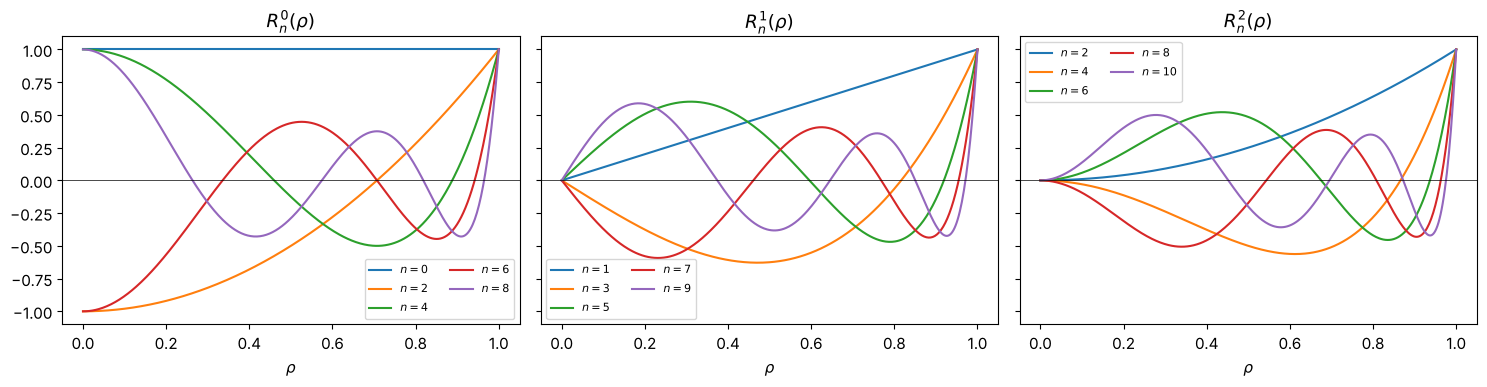

In [3]:
rho = np.linspace(0, 1, 400)
fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)
for ax, m in zip(axes, (0, 1, 2)):
    for n in range(m, m + 9, 2):
        ax.plot(rho, fringe_zernike_R_nm(n, m, rho), label=f"$n={n}$")
    ax.set_title(f"$R_n^{{{m}}}(\\rho)$"); ax.set_xlabel("$\\rho$"); ax.axhline(0, color="k", lw=0.5)
    ax.legend(fontsize=8, ncol=2)
fig.tight_layout()

## 2. Orthogonality on the disk, and how well the grid reproduces it

On the unit disk,

$$\langle Z_i | Z_j \rangle = \int_\text{disk} Z_i Z_j \, dA
  = \delta_{ij}\, \frac{\pi (1 + \delta_{m0})}{2(n + 1)},$$

which `normalization_factor()` (or `fringe_zernike_norm()`) returns. On a grid,
the integral becomes a sum and the circular edge a staircase, so orthogonality
only holds approximately. The left panel shows the Gram matrix of $Z_1 \dots Z_{36}$
on a 161 × 161 grid, normalized to unit diagonal; the off-diagonal elements are
the discretization error. The right panel shows how that error and the error of
the diagonal (compared with the analytic norm) shrink with the number of samples.

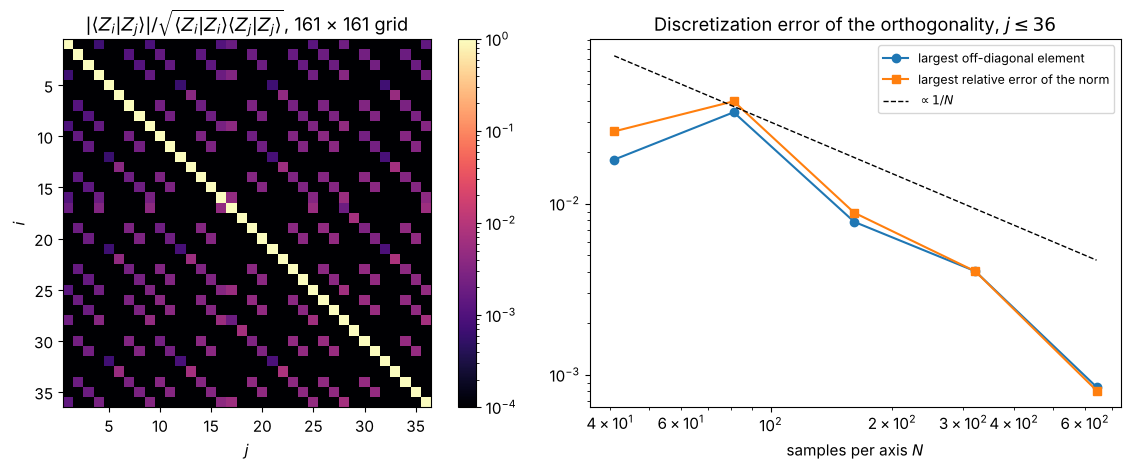

In [4]:
J36 = np.arange(1, 37)
G = gram([Zg.eval_single(j) for j in J36], xg, xg)

errs = []
Ns = (41, 81, 161, 321, 641)
for N in Ns:
    xs = grid1d(-1.02, 1.02, N)
    Zs = FringeZernikes(xs, xs)
    Gs = gram([Zs.eval_single(j) for j in J36], xs, xs)
    C = correlation(Gs)
    off = np.max(np.abs(C - np.diag(np.diag(C))))
    norm_err = np.max(np.abs(np.diag(Gs)/[fringe_zernike_norm(j) for j in J36] - 1))
    errs.append((off, norm_err))
errs = np.array(errs)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))
im = axes[0].imshow((correlation(G)), cmap="magma", norm=plt.matplotlib.colors.LogNorm(1e-4, 1),
                    extent=(0.5, 36.5, 36.5, 0.5), origin="upper")
axes[0].set_title("$|\\langle Z_i|Z_j\\rangle| / \\sqrt{\\langle Z_i|Z_i\\rangle\\langle Z_j|Z_j\\rangle}$, 161 × 161 grid")
axes[0].set_xlabel("$j$"); axes[0].set_ylabel("$i$"); fig.colorbar(im, ax=axes[0])
axes[1].loglog(Ns, errs[:, 0], "o-", label="largest off-diagonal element")
axes[1].loglog(Ns, errs[:, 1], "s-", label="largest relative error of the norm")
axes[1].loglog(Ns, 3/np.array(Ns), "k--", lw=1, label="$\\propto 1/N$")
axes[1].set_xlabel("samples per axis $N$"); axes[1].legend(fontsize=9)
axes[1].set_title("Discretization error of the orthogonality, $j \\leq 36$")
fig.tight_layout()

The error falls at least as fast as $1/N$: it is dominated by the pixels along the
staircase edge, whose share of the disk area scales like $1/N$. Basis functions
with high radial order are the worst, because they are largest at the rim.

## 3. Expanding a wavefront: least squares vs. overlap integrals

With an orthogonal basis, each coefficient can be computed independently as an
overlap integral, $c_j = \langle Z_j | W \rangle / \langle Z_j | Z_j \rangle$
(`method="DI"`, using Simpson weights). Alternatively, all coefficients are fitted
together by least squares (`method="LSTSQ"`, the default), which minimizes the
residual on the actual grid. We expand a smooth, non-polynomial "freeform"
wavefront and watch the residual as the number of terms $J$ grows.

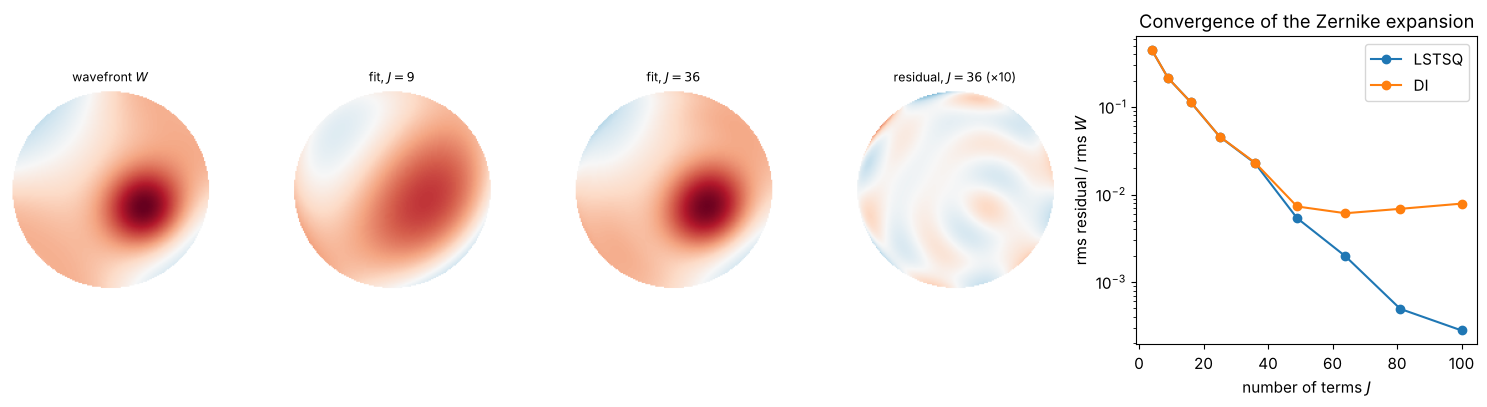

In [5]:
XX, YY = np.meshgrid(xg, xg)
W = (np.exp(-((XX - 0.35)**2 + (YY + 0.2)**2)/(2*0.3**2)) + 0.4*np.sin(2.5*XX*YY + 0.5))*mask_g

def rms(a, mask):
    return np.sqrt(np.mean(a[mask]**2))

Js = np.array([4, 9, 16, 25, 36, 49, 64, 81, 100])
res = {"LSTSQ": [], "DI": []}
fits = {}
for J in Js:
    inds = np.arange(1, J + 1)
    for method in res:
        c = Zg.coeffs_from_field(W, inds, method=method)
        Wfit = Zg(inds, c)
        res[method].append(rms(W - Wfit, mask_g))
        if method == "LSTSQ":
            fits[J] = Wfit

fig = plt.figure(figsize=(15, 4.2))
gs = fig.add_gridspec(1, 5, width_ratios=[1, 1, 1, 1, 1.7])
vmax = np.max(np.abs(W))
show(fig.add_subplot(gs[0]), W, mask_g, ext, "wavefront $W$", vmax)
for k, J in enumerate((9, 36)):
    show(fig.add_subplot(gs[1 + k]), fits[J], mask_g, ext, f"fit, $J = {J}$", vmax)
show(fig.add_subplot(gs[3]), W - fits[36], mask_g, ext, "residual, $J = 36$ (×10)", vmax/10)
ax = fig.add_subplot(gs[4])
for method, r in res.items():
    ax.semilogy(Js, np.array(r)/rms(W, mask_g), "o-", label=method)
ax.set_xlabel("number of terms $J$"); ax.set_ylabel("rms residual / rms $W$"); ax.legend()
ax.set_title("Convergence of the Zernike expansion")
fig.tight_layout()

Both methods converge quickly for this smooth wavefront. Least squares is always
at least as good, because it minimizes exactly the quantity that is plotted. The
overlap integrals stall at the level of the discretization error from Section 2:
on the grid, the Zernikes are not exactly orthogonal, and DI ignores that.

## 4. Rectangular apertures: Legendre and Chebyshev polynomials

For square or rectangular apertures (slit lamps, detectors, mask blanks), products
of 1D polynomials $P_n(x) P_m(y)$ are the natural choice. `LegendrePolynomials`
and `ChebyshevPolynomials` use a single index $j = 0, 1, 2, \dots$ that runs
through the orders: $(n, m) = (0,0), (1,0), (0,1), (2,0), (1,1), (0,2), \dots$
The half widths `a`, `b` scale the aperture.

In 1D, the Legendre polynomials $L_n$ are orthogonal with weight 1 on $[-1, 1]$.
The Chebyshev polynomials $T_n(\cos\theta) = \cos(n\theta)$ oscillate with equal
amplitude everywhere (which makes them the best choice for minimizing the
*maximum* error), but they are orthogonal only with the weight $1/\sqrt{1 - x^2}$,
which crowds them towards the edges.

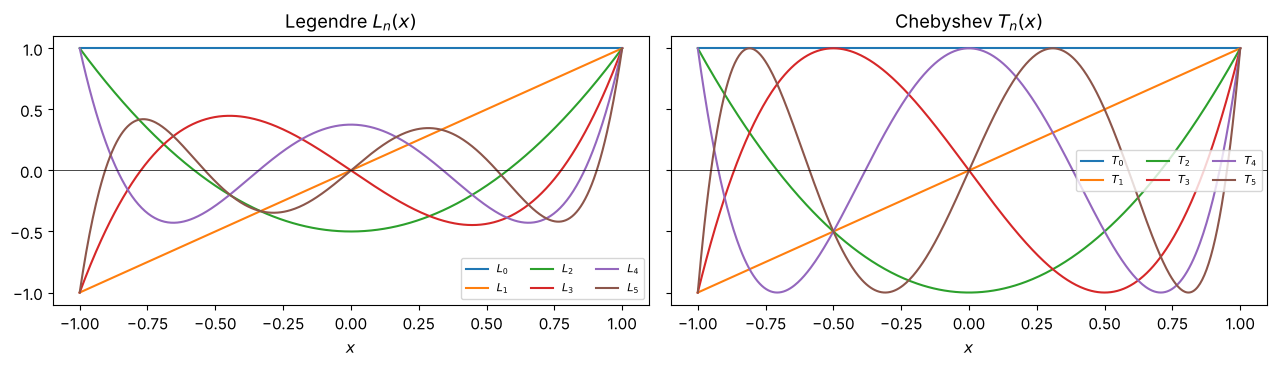

In [6]:
x1 = np.linspace(-1, 1, 500)
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8), sharey=True)
for n in range(6):
    axes[0].plot(x1, np.polynomial.legendre.Legendre.basis(n)(x1), label=f"$L_{n}$")
    axes[1].plot(x1, np.polynomial.chebyshev.Chebyshev.basis(n)(x1), label=f"$T_{n}$")
axes[0].set_title("Legendre $L_n(x)$"); axes[1].set_title("Chebyshev $T_n(x)$")
for ax in axes:
    ax.axhline(0, color="k", lw=0.5); ax.set_xlabel("$x$"); ax.legend(fontsize=8, ncol=3)
fig.tight_layout()

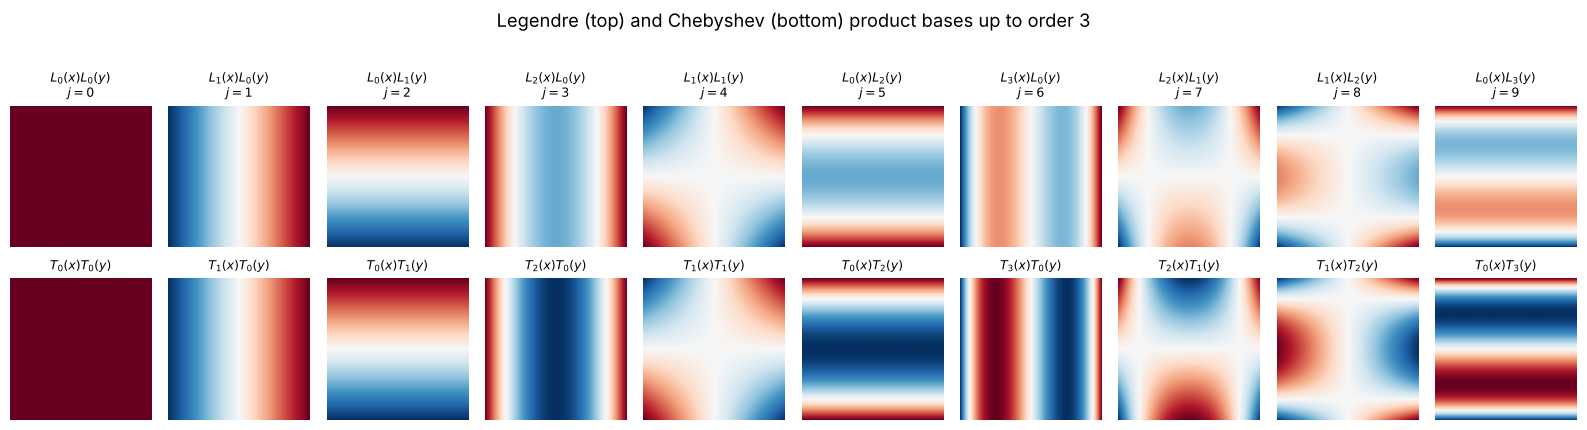

In [7]:
# a "midpoint" grid that does not contain x = ±1, where the Chebyshev weight diverges
Nq = 200
xq = np.linspace(-1, 1, Nq, endpoint=False) + 1/Nq
L = LegendrePolynomials(xq, xq)
T = ChebyshevPolynomials(xq, xq)
mask_q = L.mask.astype(bool)
ext_q = (-1, 1, -1, 1)

fig, axes = plt.subplots(2, 10, figsize=(16, 4.4))
for j in range(10):
    n, m = L.single_index_to_n_m(j)
    show(axes[0, j], L.eval_single(j), mask_q, ext_q, f"$L_{n}(x)L_{m}(y)$\n$j={j}$")
    show(axes[1, j], T.eval_single(j), mask_q, ext_q, f"$T_{n}(x)T_{m}(y)$")
fig.suptitle("Legendre (top) and Chebyshev (bottom) product bases up to order 3", y=1.02)
fig.tight_layout()

The Gram matrices of the first 28 functions (up to order 6) show the different
notions of orthogonality: Legendre is orthogonal in the plain scalar product,
Chebyshev is not, but becomes orthogonal with the weight
$w(x, y) = 1/\sqrt{(1 - x^2)(1 - y^2)}$. The functions of the two families only
overlap with others of the same parity in $x$ and in $y$, hence the
checkerboard pattern.

The Chebyshev weight diverges at the edges, which makes it hard to integrate on
a uniform grid. We therefore use the weight averaged over each pixel,
$\frac{1}{\Delta x}\int_\text{pixel} \frac{dx}{\sqrt{1-x^2}}
= \frac{\arcsin x_\text{right} - \arcsin x_\text{left}}{\Delta x}$; even so,
the off-diagonal elements only drop to the percent level on this grid, compared
with up to 90 % without the weight.

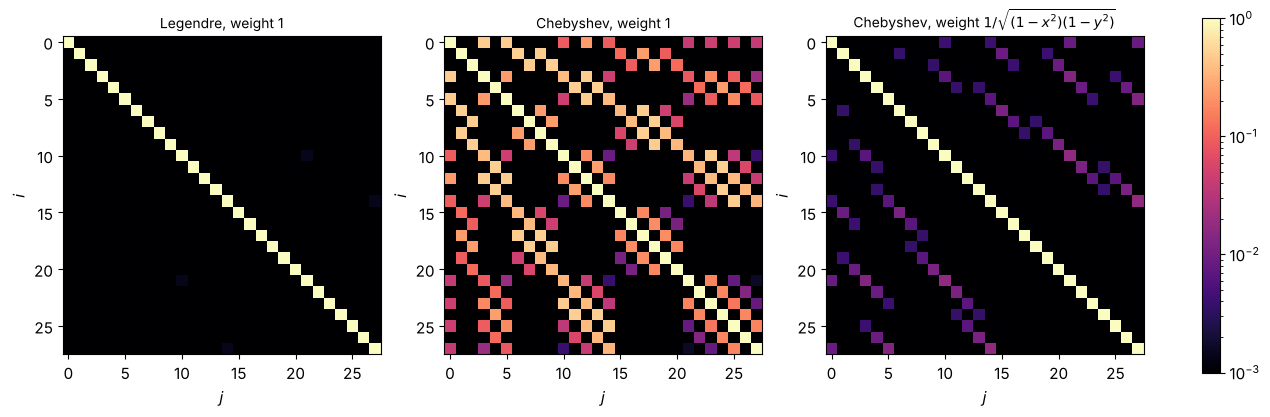

In [8]:
J28 = range(poly_basis_size(6))
QX, QY = np.meshgrid(xq, xq)
edges = np.linspace(-1, 1, Nq + 1)
w1 = np.diff(np.arcsin(edges))/np.diff(edges)   # pixel-averaged 1/sqrt(1 - x^2)
w_cheb = np.outer(w1, w1)
cases = (("Legendre, weight 1", [L.eval_single(j) for j in J28], 1.0),
         ("Chebyshev, weight 1", [T.eval_single(j) for j in J28], 1.0),
         ("Chebyshev, weight $1/\\sqrt{(1-x^2)(1-y^2)}$", [T.eval_single(j) for j in J28], w_cheb))
fig, axes = plt.subplots(1, 3, figsize=(15, 4.6))
for ax, (title, funcs, w) in zip(axes, cases):
    C = correlation(gram(funcs, xq, xq, w))
    im = ax.imshow(C, cmap="magma", norm=plt.matplotlib.colors.LogNorm(1e-3, 1), origin="upper")
    ax.set_title(title, fontsize=10); ax.set_xlabel("$j$"); ax.set_ylabel("$i$")
fig.colorbar(im, ax=axes, fraction=0.02)

The analytic norm of the Legendre product functions is
$\langle L_n L_m | L_n L_m \rangle = \frac{2a}{2n+1}\frac{2b}{2m+1}$
(`normalization_factor()`). On this grid it is reproduced to a relative
accuracy of:

In [9]:
num = np.diag(gram([L.eval_single(j) for j in J28], xq, xq))
ana = np.array([L.normalization_factor(j) for j in J28])
print(f"max |numeric/analytic - 1| for j < 28: {np.max(np.abs(num/ana - 1)):.1e}")
print(f"same via utils.scalar_product for j = 7: "
      f"{scalar_product(L.eval_single(7), L.eval_single(7), xq, xq)/L.normalization_factor(7) - 1:.1e}")

max |numeric/analytic - 1| for j < 28: 2.3e-03
same via utils.scalar_product for j = 7: -1.5e-04


## 5. Why orthogonality on the *actual* aperture matters

A popular shortcut is to describe the wavefront on a square aperture with
Zernikes defined on the circumscribed circle ($R = \sqrt 2$). This works, but the
Zernikes are not orthogonal on the square. As a consequence, a coefficient changes
every time terms are added to the fit: "the amount of defocus" depends on how many
other terms were fitted. With an orthogonal basis on the square (Legendre), the
coefficients stay put.

We fit the same smooth function on the square with an increasing number of terms
and follow two coefficients of each basis.

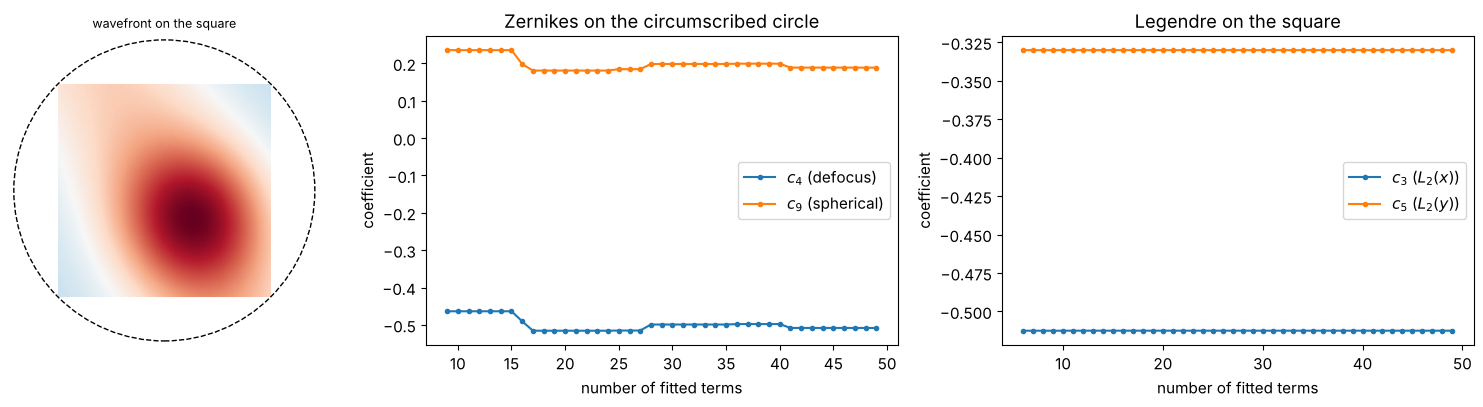

In [10]:
W_sq = np.exp(-((QX - 0.3)**2 + (QY + 0.25)**2)/(2*0.5**2)) + 0.3*np.cos(2*QX + QY)
Zsq = FringeZernikes(xq, xq, R_norm=np.sqrt(2))   # circle circumscribes the square

J_zern = np.arange(9, 50)
c_zern = np.array([Zsq.coeffs_from_field(W_sq, np.arange(1, J + 1))[[3, 8]] for J in J_zern])  # Z4, Z9
J_leg = np.arange(6, 50)
c_leg = np.array([L.coeffs_from_field(W_sq, np.arange(J))[[3, 5]] for J in J_leg])  # L2(x), L2(y)

fig, axes = plt.subplots(1, 3, figsize=(15, 4.2), gridspec_kw={"width_ratios": [1, 1.5, 1.5]})
show(axes[0], W_sq, mask_q, ext_q, "wavefront on the square")
axes[0].add_patch(plt.Circle((0, 0), np.sqrt(2), fill=False, ls="--"))
axes[0].set_xlim(-1.45, 1.45); axes[0].set_ylim(-1.45, 1.45)
axes[1].plot(J_zern, c_zern[:, 0], ".-", label="$c_4$ (defocus)")
axes[1].plot(J_zern, c_zern[:, 1], ".-", label="$c_9$ (spherical)")
axes[1].set_title("Zernikes on the circumscribed circle"); axes[1].set_xlabel("number of fitted terms")
axes[2].plot(J_leg, c_leg[:, 0], ".-", label="$c_3$ ($L_2(x)$)")
axes[2].plot(J_leg, c_leg[:, 1], ".-", label="$c_5$ ($L_2(y)$)")
axes[2].set_title("Legendre on the square"); axes[2].set_xlabel("number of fitted terms")
for ax in axes[1:]:
    ax.set_ylabel("coefficient"); ax.legend()
fig.tight_layout()

The Zernike coefficients jump whenever a function with a strong projection onto
defocus or spherical aberration enters the fit; the Legendre coefficients converge
to their final values almost immediately and then only change at the level of the
discretization error.

## 6. Arbitrary apertures: numerical orthogonalization

Telescopes have a central obscuration, segmented mirrors are hexagonal. On such
apertures the Zernikes lose their orthogonality as well. On an annulus with
obscuration ratio $\varepsilon = 0.5$, for example, defocus $Z_4 = 2\rho^2 - 1$
no longer averages to zero, so it overlaps with piston.

`NumericallyOrthogonalized` samples a basis, restricts it to a new mask and runs
a Gram-Schmidt procedure (via a QR decomposition) on the grid. The resulting
functions are exactly orthogonal on that grid and keep their original norms (or
take the norms given by `norm_func`).

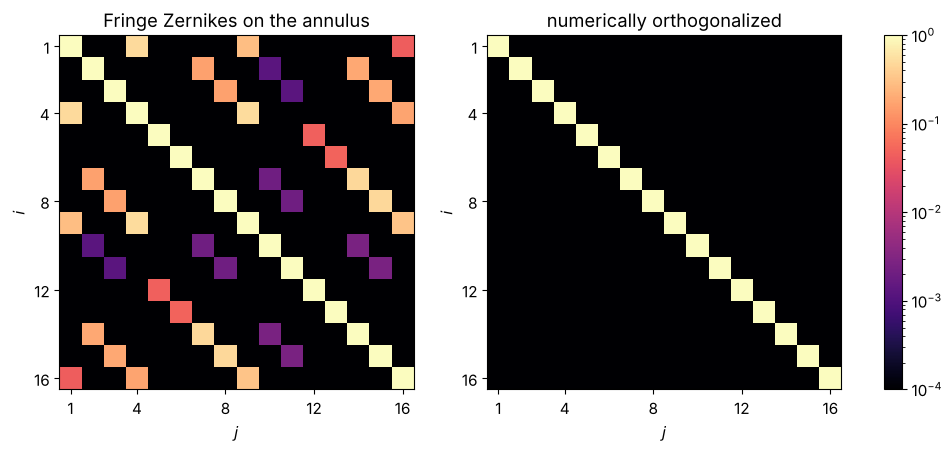

In [11]:
xa = grid1d(-1.02, 1.02, 201)
eps = 0.5
ann = annular_mask(xa, xa, 1.0, eps)
mask_a = ann.astype(bool)
ext_a = (xa[0], xa[-1], xa[0], xa[-1])
J16 = np.arange(1, 17)

Za = FringeZernikes(xa, xa)
Za_orth = NumericallyOrthogonalized(xa, xa, FringeZernikes, J16, new_mask=ann)

G_plain = gram([Za.eval_single(j)*ann for j in J16], xa, xa)
G_orth = gram([Za_orth.eval_single(j) for j in J16], xa, xa)

fig, axes = plt.subplots(1, 2, figsize=(11, 4.6))
for ax, G_, title in zip(axes, (G_plain, G_orth), ("Fringe Zernikes on the annulus", "numerically orthogonalized")):
    im = ax.imshow((correlation(G_)), cmap="magma", norm=plt.matplotlib.colors.LogNorm(1e-4, 1),
                   extent=(0.5, 16.5, 16.5, 0.5), origin="upper")
    ax.set_title(title); ax.set_xlabel("$j$"); ax.set_ylabel("$i$")
    ax.set_xticks([1, 4, 8, 12, 16]); ax.set_yticks([1, 4, 8, 12, 16])
fig.colorbar(im, ax=axes, fraction=0.03)

The orthogonalized functions are the (numerical) **annular Zernike polynomials**.
For defocus, Gram-Schmidt only has to remove the mean over the annulus: since
$\langle \rho^2 \rangle = (1 + \varepsilon^2)/2$ there, the result must be
proportional to $2\rho^2 - 1 - \varepsilon^2$, which is the analytic annular
defocus. Higher orders change more, e.g. spherical aberration, which has to be
made orthogonal to both piston and defocus.

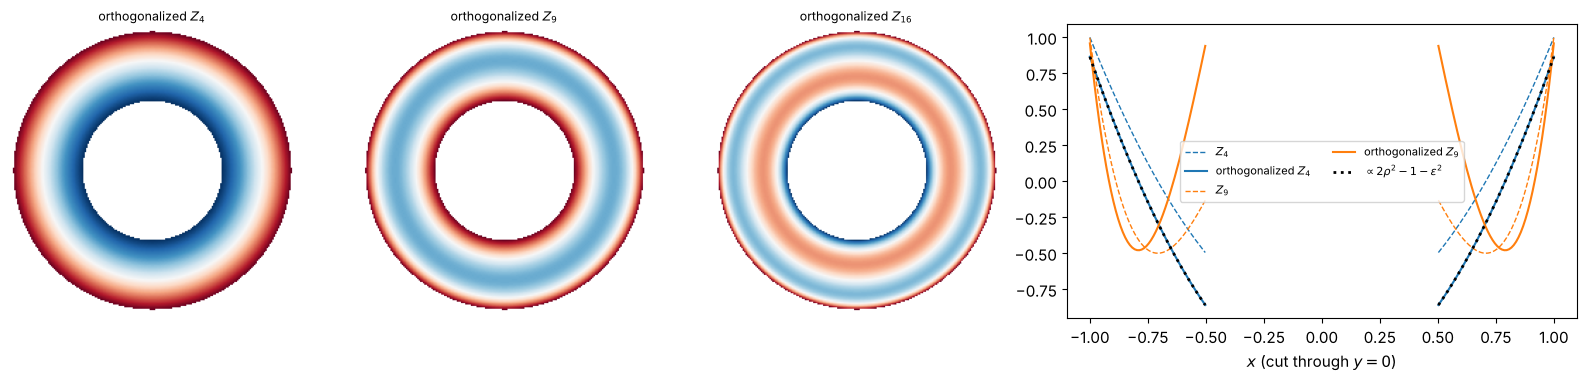

In [12]:
row = len(xa)//2
fig, axes = plt.subplots(1, 4, figsize=(16, 3.8), gridspec_kw={"width_ratios": [1, 1, 1, 1.8]})
for ax, j in zip(axes[:2], (4, 9)):
    show(ax, Za_orth.eval_single(j), mask_a, ext_a, f"orthogonalized $Z_{{{j}}}$")
show(axes[2], Za_orth.eval_single(16), mask_a, ext_a, "orthogonalized $Z_{16}$")
r = xa[mask_a[row]]
for j, col in ((4, "C0"), (9, "C1")):
    axes[3].plot(xa, np.where(mask_a[row], Za.eval_single(j)[row], np.nan), "--", color=col, lw=1,
                 label=f"$Z_{{{j}}}$")
    axes[3].plot(xa, np.where(mask_a[row], Za_orth.eval_single(j)[row], np.nan), color=col,
                 label=f"orthogonalized $Z_{{{j}}}$")
ref = 2*xa**2 - 1 - eps**2
scale = np.sum(Za_orth.eval_single(4)[row][mask_a[row]]*ref[mask_a[row]])/np.sum(ref[mask_a[row]]**2)
axes[3].plot(xa, np.where(mask_a[row], scale*ref, np.nan), "k:", lw=2, label="$\\propto 2\\rho^2 - 1 - \\varepsilon^2$")
axes[3].set_xlabel("$x$ (cut through $y = 0$)"); axes[3].legend(fontsize=8, ncol=2)
fig.tight_layout()

A hexagonal aperture works the same way: any mask, e.g. from `mask_from_polygon()`,
can be used.

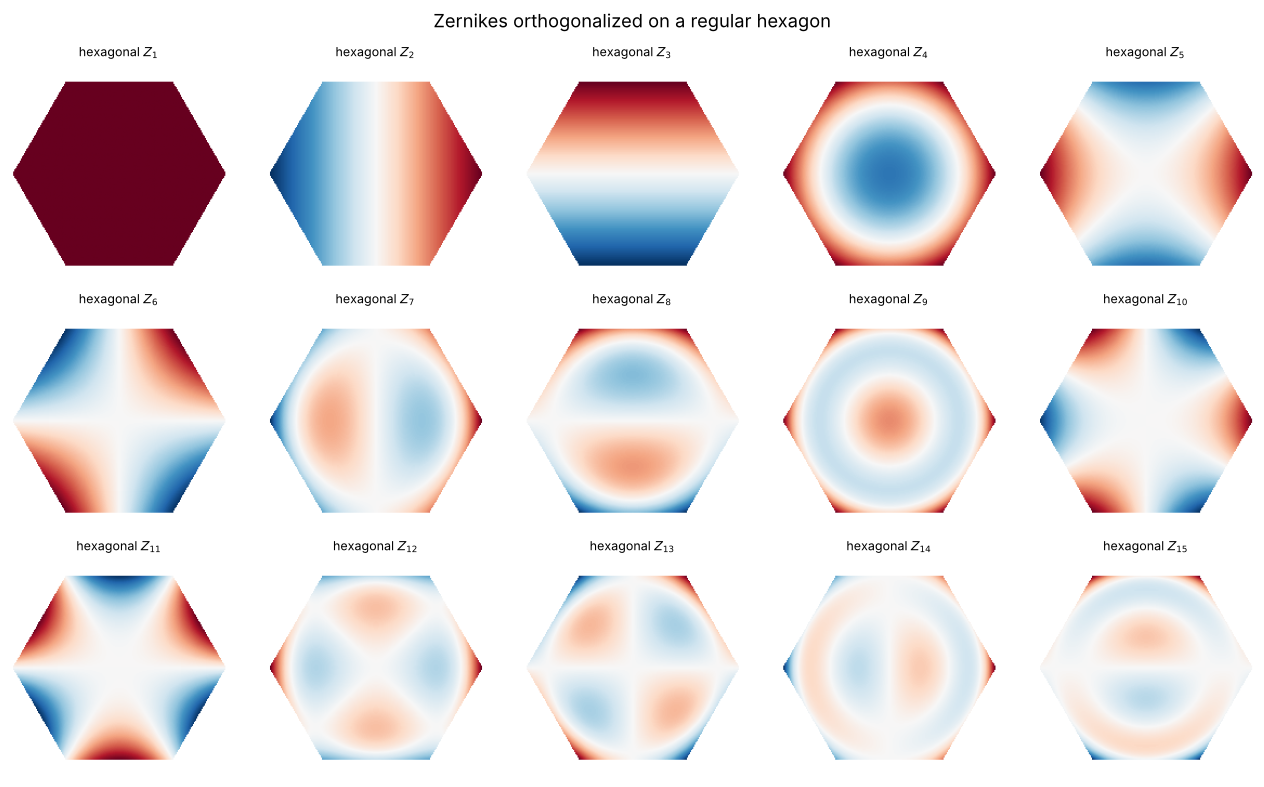

In [13]:
phi_hex = np.linspace(0, 2*np.pi, 7)
hexagon = mask_from_polygon(xa, xa, np.cos(phi_hex), np.sin(phi_hex))
mask_h = hexagon.astype(bool)
J15 = np.arange(1, 16)
Zh_orth = NumericallyOrthogonalized(xa, xa, FringeZernikes, J15, new_mask=hexagon)

fig, axes = plt.subplots(3, 5, figsize=(13, 8))
for ax, j in zip(axes.flat, J15):
    show(ax, Zh_orth.eval_single(j), mask_h, ext_a, f"hexagonal $Z_{{{j}}}$")
fig.suptitle("Zernikes orthogonalized on a regular hexagon")
fig.tight_layout()

Again the coefficients tell the story. We fit a wavefront on the annulus with the
plain Zernikes (restricted to the annulus) and with the orthogonalized set, and
follow the piston and defocus coefficients. With plain Zernikes, "piston" is not
the mean of the wavefront and changes with the number of terms; with the
orthogonalized basis it is the mean, independent of $J$.

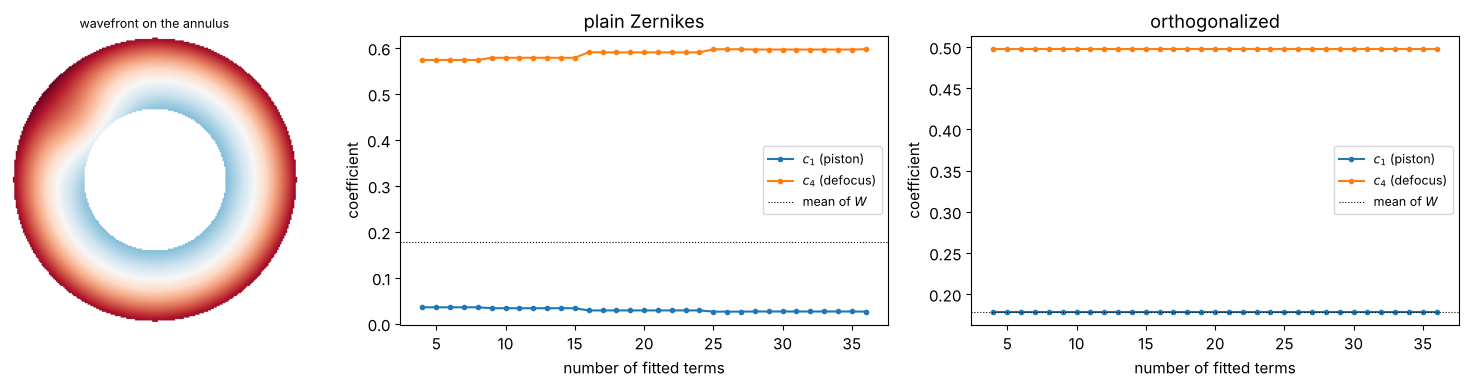

In [14]:
XA, YA = np.meshgrid(xa, xa)
W_a = (0.6*(2*(XA**2 + YA**2) - 1) + 0.3*np.exp(-((XA + 0.5)**2 + (YA - 0.4)**2)/0.1))*ann
J36a = np.arange(1, 37)
Za_orth36 = NumericallyOrthogonalized(xa, xa, FringeZernikes, J36a, new_mask=ann)

def masked_lstsq(basis, inds, field, mask):
    M = np.array([basis.eval_single(j)[mask] for j in inds]).T
    return np.linalg.lstsq(M, field[mask], rcond=None)[0]

Jfit = np.arange(4, 37)
c_plain = np.array([masked_lstsq(Za, np.arange(1, J + 1), W_a, mask_a)[[0, 3]] for J in Jfit])
c_orth = np.array([Za_orth36.coeffs_from_field(W_a, np.arange(1, J + 1))[[0, 3]] for J in Jfit])

fig, axes = plt.subplots(1, 3, figsize=(15, 4), gridspec_kw={"width_ratios": [1, 1.5, 1.5]})
show(axes[0], W_a, mask_a, ext_a, "wavefront on the annulus")
for ax, c, title in ((axes[1], c_plain, "plain Zernikes"), (axes[2], c_orth, "orthogonalized")):
    ax.plot(Jfit, c[:, 0], ".-", label="$c_1$ (piston)")
    ax.plot(Jfit, c[:, 1], ".-", label="$c_4$ (defocus)")
    ax.axhline(W_a[mask_a].mean(), color="k", lw=0.8, ls=":", label="mean of $W$")
    ax.set_title(title); ax.set_xlabel("number of fitted terms"); ax.set_ylabel("coefficient")
    ax.legend(fontsize=9)
fig.tight_layout()

Note that `masked_lstsq()` above is needed for the plain Zernikes: `FringeZernikes`
are non-zero in the central hole, and `coeffs_from_field()` fits on the whole
grid. The orthogonalized functions vanish outside their new mask, so the built-in
fit works directly.

## 7. Rescaling: coefficients as peak values

With the Fringe normalization, a coefficient $c_j$ is the peak value of the term
on the unit circle. On a smaller or non-circular aperture this is no longer true:
on the hexagon inscribed in the unit circle, most Zernikes never reach $|Z_j| = 1$.
`RescaledBasis` wraps a basis, applies a new mask and rescales every function
with `scale_val_func(j)/scale_func(B_j)`. With `scale_func = max |B_j|` and
`scale_val_func = 1`, each coefficient is again the peak deviation on the aperture.

max |Z_j| of the rescaled functions: [1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]


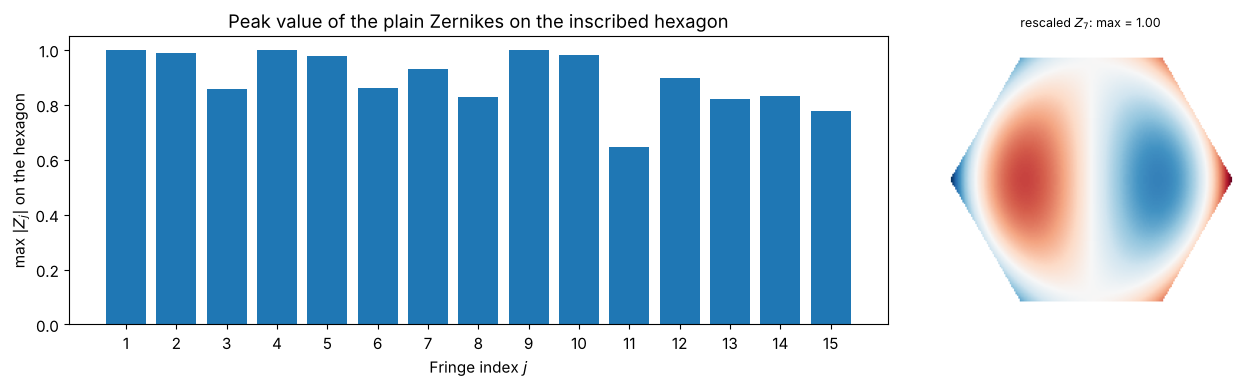

In [15]:
Zh_rescaled = RescaledBasis(xa, xa, FringeZernikes, mask=hexagon,
                            scale_func=lambda v: np.max(np.abs(v)), scale_val_func=lambda j: 1.0)
peak_plain = [np.max(np.abs(Za.eval_single(j)*hexagon)) for j in J15]
with contextlib.redirect_stdout(io.StringIO()):   # RescaledBasis prints every factor
    peak_rescaled = [np.max(np.abs(Zh_rescaled.eval_single(j))) for j in J15]
    Z7_hex = Zh_rescaled.eval_single(7)
print("max |Z_j| of the rescaled functions:", np.round(peak_rescaled, 3))

fig, axes = plt.subplots(1, 2, figsize=(13, 4), gridspec_kw={"width_ratios": [2.2, 1]})
axes[0].bar(J15, peak_plain)
axes[0].set_xticks(J15); axes[0].set_xlabel("Fringe index $j$"); axes[0].set_ylabel("max $|Z_j|$ on the hexagon")
axes[0].set_title("Peak value of the plain Zernikes on the inscribed hexagon")
show(axes[1], Z7_hex, mask_h, ext_a, f"rescaled $Z_7$: max = {np.max(np.abs(Z7_hex)):.2f}", vmax=1)
fig.tight_layout()

Functions that peak at the rim in the direction of a vertex (piston, $x$ tilt,
defocus, spherical aberration) still reach 1. The others lose amplitude: $y$ tilt
peaks at the top edge, $\sqrt 3/2 \approx 0.87$, and the trefoil $Z_{11}$, whose
maxima point at the edge midpoints, reaches only $(\sqrt 3/2)^3 \approx 0.65$.
After rescaling, all of them have a peak value of exactly 1.

## 8. Scattered data

Measurements do not always come on a grid: a coordinate measuring machine probes a
surface at a few hundred points, a Shack-Hartmann sensor at its lenslet positions.
`coeffs_from_scattered()` fits the coefficients directly to such data, and
`B(indices, coeffs)` then gives the result on any grid. We simulate 120 noisy
measurements of a wavefront built from 15 Zernikes.

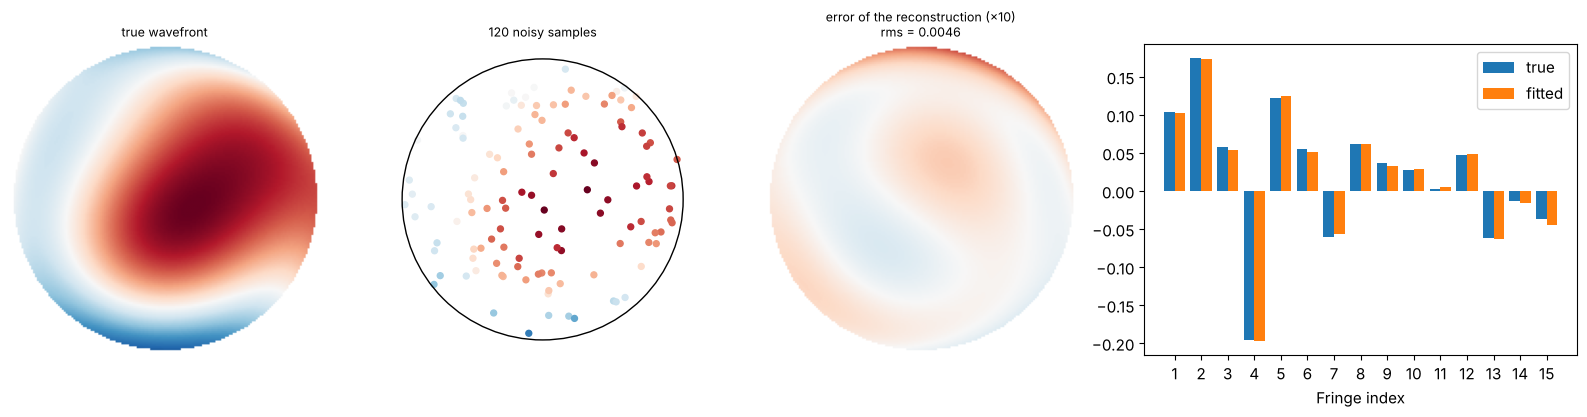

In [16]:
rng = np.random.default_rng(1)
J15_true = np.arange(1, 16)
c_true = rng.normal(0, 0.3, 15)/np.sqrt(J15_true)
noise = 0.02

def sample_disk(n):
    r, phi = np.sqrt(rng.random(n)), 2*np.pi*rng.random(n)
    return r*np.cos(phi), r*np.sin(phi)

xs, ys = sample_disk(120)
data = Zg(J15_true, c_true, xs, ys) + rng.normal(0, noise, xs.shape)
c_fit = Zg.coeffs_from_scattered(xs, ys, data, J15_true)

W_true = Zg(J15_true, c_true)
W_rec = Zg(J15_true, c_fit)
vmax = np.max(np.abs(W_true[mask_g]))
fig, axes = plt.subplots(1, 4, figsize=(16, 4), gridspec_kw={"width_ratios": [1, 1, 1, 1.4]})
show(axes[0], W_true, mask_g, ext, "true wavefront", vmax)
axes[1].scatter(xs, ys, c=data, cmap="RdBu_r", vmin=-vmax, vmax=vmax, s=18)
axes[1].add_patch(plt.Circle((0, 0), 1, fill=False)); axes[1].set_aspect("equal"); axes[1].axis("off")
axes[1].set_title("120 noisy samples", fontsize=9)
show(axes[2], W_true - W_rec, mask_g, ext, f"error of the reconstruction (×10)\nrms = {rms(W_true - W_rec, mask_g):.4f}", vmax/10)
axes[3].bar(J15_true - 0.2, c_true, 0.4, label="true")
axes[3].bar(J15_true + 0.2, c_fit, 0.4, label="fitted")
axes[3].set_xticks(J15_true); axes[3].set_xlabel("Fringe index"); axes[3].legend()
fig.tight_layout()

How many samples are needed? The fit has as many unknowns as terms. With too few
points the problem is badly conditioned and the noise is amplified enormously;
with many points the error decreases like $1/\sqrt{N_\text{points}}$, as for any
averaging of noise. The same 15-term wavefront is fitted with $J = 15$ and with
$J = 36$ terms (the extra 21 coefficients should come out as zero).

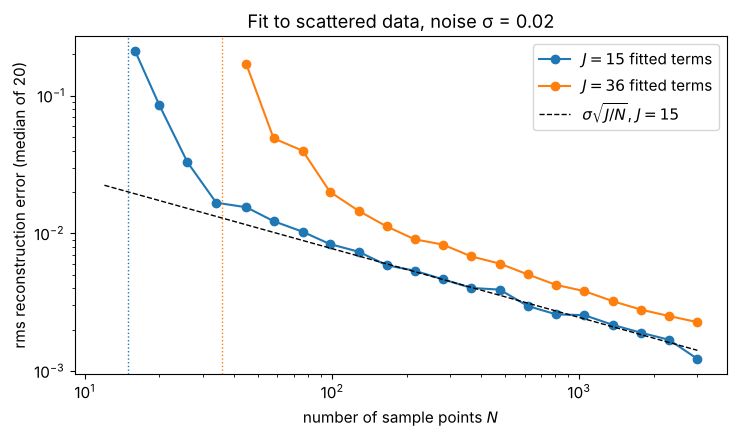

In [17]:
n_pts = np.unique(np.round(np.logspace(np.log10(12), np.log10(3000), 22)).astype(int))
curves = {}
for J in (15, 36):
    inds = np.arange(1, J + 1)
    errs = []
    for n in n_pts:
        e = []
        for trial in range(20):
            xs_, ys_ = sample_disk(n)
            d = Zg(J15_true, c_true, xs_, ys_) + rng.normal(0, noise, n)
            if n < J:
                e.append(np.nan); continue
            c = Zg.coeffs_from_scattered(xs_, ys_, d, inds)
            e.append(rms(W_true - Zg(inds, c), mask_g))
        errs.append(np.nanmedian(e) if np.isfinite(e).any() else np.nan)
    curves[J] = np.array(errs)

fig, ax = plt.subplots(figsize=(7.5, 4.5))
for J, e in curves.items():
    ax.loglog(n_pts, e, "o-", label=f"$J = {J}$ fitted terms")
    ax.axvline(J, color=ax.lines[-1].get_color(), ls=":", lw=1)
ax.loglog(n_pts, noise*np.sqrt(15/n_pts), "k--", lw=1, label="$\\sigma\\sqrt{J/N}$, $J = 15$")
ax.set_xlabel("number of sample points $N$"); ax.set_ylabel("rms reconstruction error (median of 20)")
ax.set_title(f"Fit to scattered data, noise σ = {noise}"); ax.legend()
fig.tight_layout()

Close to $N = J$ (dotted lines) the error explodes; a few times more points than
terms are needed before the fit is limited by the noise alone. Fitting more terms
than the wavefront contains costs accuracy at a given $N$, because the extra
coefficients fit the noise.

## 9. Presampling for speed

Every `eval_single()` call recomputes the polynomial on the grid. In iterative
algorithms (fits in a loop, optimization over coefficients) it pays to sample the
needed functions once: `PresampledBasisSet` wraps any basis and replaces the
evaluation by a dictionary lookup, while passing through the mask and norms.

In [18]:
xb = grid1d(-1, 1, 512)
inds = np.arange(1, 37)
Z_live = FringeZernikes(xb, xb)
Z_pre = PresampledBasisSet(xb, xb, FringeZernikes, inds)
coeffs = rng.normal(size=36)

for name, B in (("FringeZernikes", Z_live), ("PresampledBasisSet", Z_pre)):
    t0 = time.perf_counter()
    for _ in range(5):
        B(inds, coeffs)
    print(f"{name:20s}: {(time.perf_counter() - t0)/5*1e3:6.1f} ms per evaluation of 36 terms on 512 × 512")
print("identical results:", np.allclose(Z_live(inds, coeffs), Z_pre(inds, coeffs)))

FringeZernikes      :  298.2 ms per evaluation of 36 terms on 512 × 512
PresampledBasisSet  :   38.3 ms per evaluation of 36 terms on 512 × 512


identical results: True


## Summary

- Zernikes, Legendre and Chebyshev polynomials are orthogonal on their own
  aperture (disk or rectangle), Chebyshev only with its weight function. On a grid,
  orthogonality holds up to a discretization error $\propto 1/N$ from the
  aperture edge.
- Least-squares fitting (`"LSTSQ"`) is the robust default; overlap integrals
  (`"DI"`) only work as well as the discrete orthogonality.
- On any other aperture (square, annulus, hexagon), a basis that is not orthogonal
  there gives coefficients that depend on which other terms are fitted.
  `NumericallyOrthogonalized` fixes that for an arbitrary mask; `RescaledBasis`
  restores the meaning of a coefficient as a peak value.
- Scattered data can be fitted directly, with a few times more points than terms.

The classes `Polynomials` (plain monomials) and the function
`basis_from_generating_function()` exist in the module but are not implemented
yet.